In [ ]:
# import cryojax
# import cryojax.simulator as cxs

/usr/local/Caskroom/miniforge/base/envs/cryojax-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
    # from cryojax.constants import b_factor_to_variance
    # from cryojax.coordinates import make_coordinate_grid
    # from cryojax.io import read_atoms_from_pdb
    # from cryojax.ndimage import downsample_with_fourier_cropping, ifftn, irfftn
    # from cryojax.simulator import (
    #     BasicImageConfig,
    #     FourierVoxelGridVolume,
    #     GaussianMixtureProjection,
    #     GaussianMixtureVolume,
    #     PengAtomicVolume,
    #     PengScatteringFactorParameters,
    #     RealVoxelGridVolume,
    # )

/var/folders/bg/cb0cr7ls61352lhy50167r0c0000gn/T/ipykernel_44030/3863366939.py:4: DeprecationWarning: 'downsample_with_fourier_cropping' is deprecatedhas been renamed to 'fourier_crop_downsample'. The old name will be deprecated in cryoJAX 0.6.0.
  from cryojax.ndimage import downsample_with_fourier_cropping, ifftn, irfftn
/var/folders/bg/cb0cr7ls61352lhy50167r0c0000gn/T/ipykernel_44030/3863366939.py:5: DeprecationWarning: 'PengAtomicVolume' is deprecated and will be removed in cryoJAX 0.6.0. To achieve identical functionality, use `GaussianMixtureVolume.from_tabulated_parameters`. This is a breaking change if you are directly using `PengAtomicVolume.__init__`.
  from cryojax.simulator import (
/var/folders/bg/cb0cr7ls61352lhy50167r0c0000gn/T/ipykernel_44030/3863366939.py:5: DeprecationWarning: 'PengScatteringFactorParameters' has been moved to `cryojax.constants` will be removed from `cryojax.simulator` in cryoJAX 0.6.0.
  from cryojax.simulator import (


In [ ]:
import warnings

import cryojax.simulator as cxs
import equinox as eqx
import jax
import jax.numpy as jnp
import numpy as np
# import pytest
from cryojax.atom_util import split_atoms_by_element
from cryojax.constants import PengScatteringFactorParameters
from cryojax.io import read_atoms_from_pdb
from cryojax.ndimage import crop_to_shape, irfftn, operators as op
# from jaxtyping import Array

In [6]:
atom_positions, _ = read_atoms_from_pdb('1uao_assembly.pdb', center=True, loads_properties=False, selection_string='not element H')


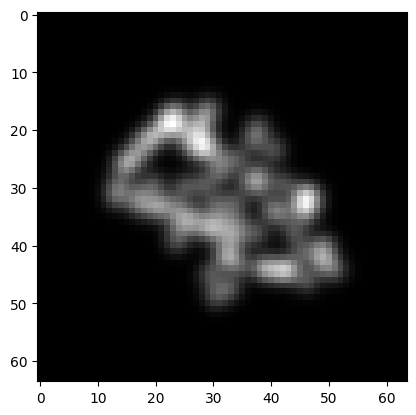

In [7]:
    
pixel_size, shape = 0.35, (32, 32)
pad_options = dict(shape=(64, 64))
image_config = cxs.BasicImageConfig(
    shape, pixel_size, voltage_in_kilovolts=300.0, pad_options=pad_options
)
amplitude, b_factor = 1.0, 25.0
atom_volume, fft_integrator = (
    cxs.IndependentAtomVolume(
        position_pytree=atom_positions,
        scattering_factor_pytree=op.FourierGaussian(
            amplitude=amplitude, b_factor=b_factor
        ),
    ),
    cxs.FFTAtomProjection(eps=1e-4),
)

proj_ref = fft_integrator.integrate(
        atom_volume, image_config, outputs_real_space=True
    )

import matplotlib.pyplot as plt
plt.imshow(proj_ref, cmap='gray')

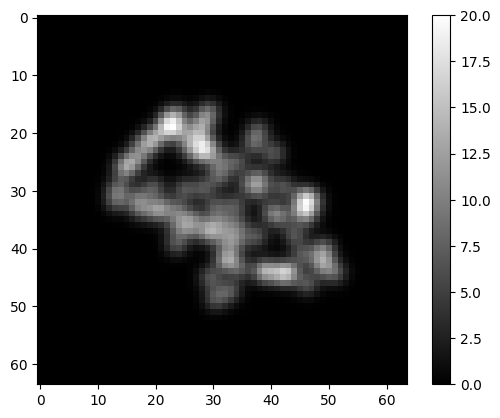

In [8]:
width = 0.5
volume = gaussian_volume = cxs.GaussianMixtureVolume(
            atom_positions,
            amplitudes=1.0,
            variances=width**2,
        )
gaussian_integrator = cxs.GaussianMixtureProjection()
proj_ref = gaussian_integrator.integrate(
            gaussian_volume, image_config, outputs_real_space=True
        )
import matplotlib.pyplot as plt
plt.imshow(proj_ref, cmap='gray')
plt.colorbar()

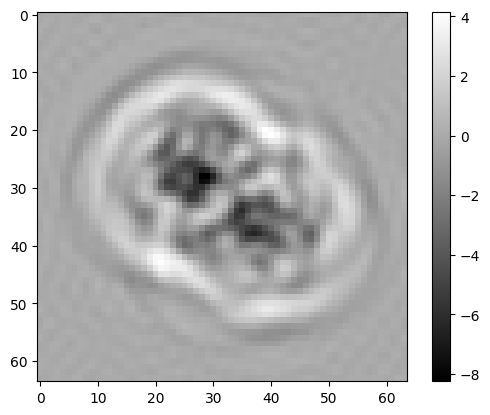

In [9]:
pixel_size, shape = 0.5, (64, 64)
pad_options = dict(shape=(64, 64))
image_config = cxs.BasicImageConfig(
    shape, pixel_size, voltage_in_kilovolts=300.0, pad_options=pad_options
)
from cryojax.ndimage.operators import FourierGaussian
amplitude, b_factor = 1.0, 10.0
envelope = FourierGaussian(amplitude=amplitude, b_factor=b_factor)
transfer_theory = cxs.ContrastTransferTheory(
        cxs.AstigmaticCTF(defocus_in_angstroms=2000),
        envelope=envelope,
    )
image_model = cxs.make_image_model(
    gaussian_volume,
    image_config,
    pose=cxs.QuaternionPose(),
    transfer_theory=transfer_theory,    

)
plt.imshow(image_model.simulate(), cmap='gray')
plt.colorbar()

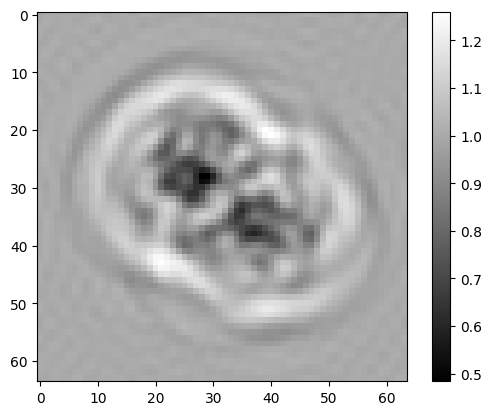

AssertionError: 

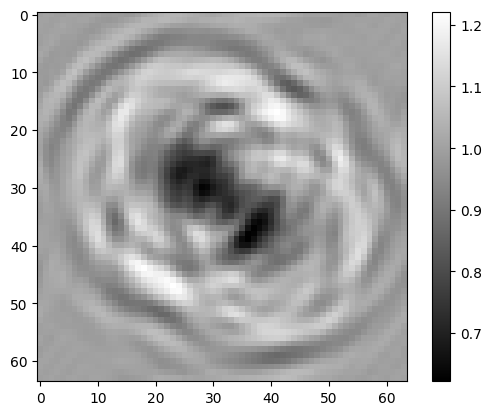

In [88]:

old_image_model = cxs.make_image_model(
    gaussian_volume,
    image_config,
    pose=cxs.QuaternionPose(),
    transfer_theory=transfer_theory,    
    simulates_quantity=True,
    quantity_mode='intensity'

)
plt.imshow(old_image_model.simulate(), cmap='gray')
plt.colorbar()
plt.show()
from joint_gradient_descent import apply_all_cv
image_model = apply_all_cv(
    old_image_model,
    wxyz=jnp.array([1.0, 0.0, 0.0, 0.0]),
    cv_scalar=0.0,
    defocus_scalar=2750.0,
    offset_x_in_angstroms=0.0,
    offset_y_in_angstroms=0,

)
plt.imshow(image_model.simulate(), cmap='gray')
plt.colorbar()

assert np.allclose(old_image_model.simulate(), image_model.simulate())

# grid landscape of two variables

In [89]:
# n = 10
# cv_grid = jnp.linspace(-4, 4, n)
# ty_grid = jnp.linspace(-5, 5, n)
# l2_landscape = jnp.zeros((len(cv_grid), len(ty_grid)))
# proj_ref = image_model.simulate()
# for cv in cv_grid:
#     for ty in ty_grid:
#         new_image_model = apply_all_cv(
#             image_model,
#             wxyz=jnp.array([1.0, 0.0, 0.0, 0.0]),
#             cv_scalar=cv,
#             defocus_scalar=500.0,
#             offset_x_in_angstroms=0.0,
#             offset_y_in_angstroms=ty,
#         )
#         diff = new_image_model.simulate() - proj_ref
#         l2_landscape = l2_landscape.at[cv_grid==cv, ty_grid==ty].set(jnp.linalg.norm(diff))

# import matplotlib.pyplot as plt
# plt.imshow(l2_landscape, extent=(ty_grid[0], ty_grid[-1], cv_grid[0], cv_grid[-1]), origin='lower', aspect='auto')
# plt.colorbar()
# plt.xlabel('Translation Y (Angstroms)')
# plt.ylabel('Defocus (Microns)')
# plt.title('L2 Loss Landscape')
# plt.show()




In [90]:


# Example: same grids
n = 30
cv_grid = jnp.linspace(-4, 4, n)
other_grid = jnp.linspace(-5, 5, n)
proj_ref = image_model.simulate()

# Define a single evaluation function
def eval_l2(cv, other):
    # wxyz=jnp.array([1.0-other, other, other, other])
    # wxyz /= jnp.linalg.norm(wxyz)
    new_image_model = apply_all_cv(
        image_model,
        wxyz=jnp.array([1.0,0,0,0]),
        cv_scalar=cv,
        defocus_scalar=2000,
        offset_x_in_angstroms=0,
        offset_y_in_angstroms=other,
    )
    diff = new_image_model.simulate() - proj_ref
    return jnp.linalg.norm(diff)

# First vmap over ty for a fixed cv
eval_l2_over_other = jax.vmap(eval_l2, in_axes=(None, 0))

# Then vmap over cv (to get a 2D matrix)
eval_l2_over_cv_other = jax.vmap(eval_l2_over_other, in_axes=(0, None))

# Compute all at once
l2_landscape = eval_l2_over_cv_other(cv_grid, other_grid)

# (Optional) Compile with JIT for big speedup
eval_l2_over_cv_other_jit = jax.jit(eval_l2_over_cv_other)
l2_landscape = eval_l2_over_cv_other_jit(cv_grid, other_grid)


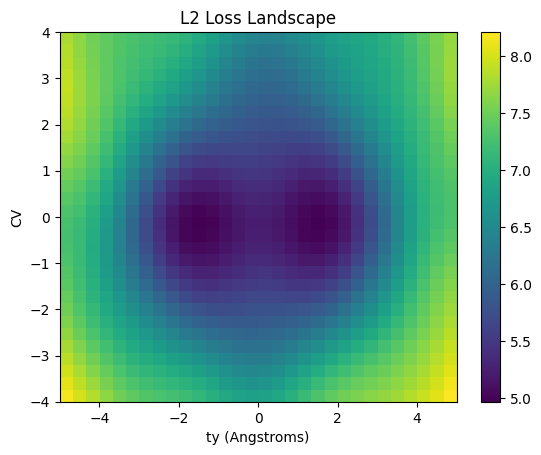

In [91]:
import matplotlib.pyplot as plt
plt.imshow(l2_landscape, extent=(other_grid[0], other_grid[-1], cv_grid[0], cv_grid[-1]), origin='lower', aspect='auto')
plt.colorbar()
plt.xlabel('ty (Angstroms)')
plt.ylabel('CV')
plt.title('L2 Loss Landscape')
plt.show()

In [58]:
# from cryojax.simulator._pose import SO3
# SO3(
from cryojax.rotations._utils import convert_quaternion_to_euler_angles
eqx.tree_at(lambda im: im.pose, image_model, cxs.QuaternionPose(wxyz=jnp.array([1.0, 0.0, 0.0, 0.0])))
# cxs.QuaternionPose(wxyz=jnp.array([1.0, 0.0, 0.0, 0.0])).wxyz

IntensityImageModel(
  volume_parametrization=GaussianMixtureVolume(
    positions=f32[770,3], amplitudes=f32[770,1], variances=f32[770,1]
  ),
  pose=QuaternionPose(offset_in_angstroms=f32[2], wxyz=f32[4]),
  image_config=BasicImageConfig(
    shape=(64, 64),
    pixel_size=f32[],
    voltage_in_kilovolts=f32[],
    grid_helper=None,
    pad_options={'grid_helper': None, 'mode': 'constant', 'shape': (64, 64)}
  ),
  scattering_theory=WeakPhaseScatteringTheory(
    volume_integrator=GaussianMixtureProjection(
      use_error_functions=True, shape=None, n_batches=1
    ),
    transfer_theory=ContrastTransferTheory(
      ctf=AstigmaticCTF(
        defocus_in_angstroms=500.0,
        astigmatism_in_angstroms=f32[],
        astigmatism_angle=f32[],
        spherical_aberration_in_mm=f32[]
      ),
      envelope=FourierGaussian(amplitude=f32[], b_factor=f32[]),
      amplitude_contrast_ratio=weak_f32[],
      phase_shift=f32[]
    )
  ),
  applies_translation=True,
  normalizes_signal=Fal

In [268]:
cxs.QuaternionPose().from_rotation(SO3.from_matrix(jnp.eye(3))).wxyz

Array([1., 0., 0., 0.], dtype=float32)

In [241]:
cxs.EulerAnglePose(offset_x_in_angstroms=10).offset_in_angstroms

Array([10.,  0.], dtype=float32)

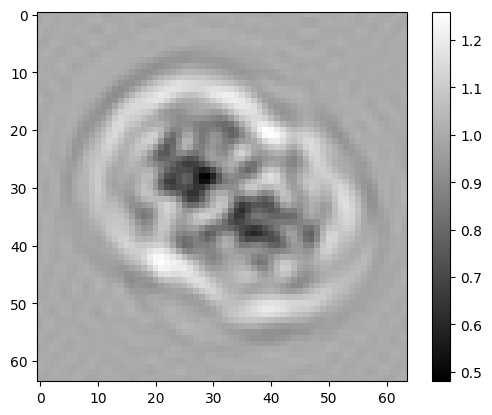

In [213]:
from cryojax.simulator import WeakPhaseScatteringTheory
scattering_theory = WeakPhaseScatteringTheory(gaussian_integrator, transfer_theory)
image_ref = scattering_theory.compute_intensity_spectrum(gaussian_volume, image_config)
from cryojax.ndimage import irfftn

# image_ref = image_ref.at[0,0].set(0.0)
plt.imshow(irfftn(image_ref), cmap='gray')
plt.colorbar()

In [228]:
scattering_theory

WeakPhaseScatteringTheory(
  volume_integrator=GaussianMixtureProjection(
    use_error_functions=True, shape=None, n_batches=1
  ),
  transfer_theory=ContrastTransferTheory(
    ctf=AstigmaticCTF(
      defocus_in_angstroms=f32[],
      astigmatism_in_angstroms=f32[],
      astigmatism_angle=f32[],
      spherical_aberration_in_mm=f32[]
    ),
    envelope=FourierGaussian(amplitude=f32[], b_factor=f32[]),
    amplitude_contrast_ratio=weak_f32[],
    phase_shift=f32[]
  )
)

In [217]:
eqx.tree_at(lambda m: m.transfer_theory.ctf.defocus_in_angstroms, scattering_theory, 2500.0)

# scattering_theory.transfer_theory.ctf.defocus_in_angstroms

WeakPhaseScatteringTheory(
  volume_integrator=GaussianMixtureProjection(
    use_error_functions=True, shape=None, n_batches=1
  ),
  transfer_theory=ContrastTransferTheory(
    ctf=AstigmaticCTF(
      defocus_in_angstroms=2500.0,
      astigmatism_in_angstroms=f32[],
      astigmatism_angle=f32[],
      spherical_aberration_in_mm=f32[]
    ),
    envelope=FourierGaussian(amplitude=f32[], b_factor=f32[]),
    amplitude_contrast_ratio=weak_f32[],
    phase_shift=f32[]
  )
)

In [218]:
scattering_theory

WeakPhaseScatteringTheory(
  volume_integrator=GaussianMixtureProjection(
    use_error_functions=True, shape=None, n_batches=1
  ),
  transfer_theory=ContrastTransferTheory(
    ctf=AstigmaticCTF(
      defocus_in_angstroms=f32[],
      astigmatism_in_angstroms=f32[],
      astigmatism_angle=f32[],
      spherical_aberration_in_mm=f32[]
    ),
    envelope=FourierGaussian(amplitude=f32[], b_factor=f32[]),
    amplitude_contrast_ratio=weak_f32[],
    phase_shift=f32[]
  )
)

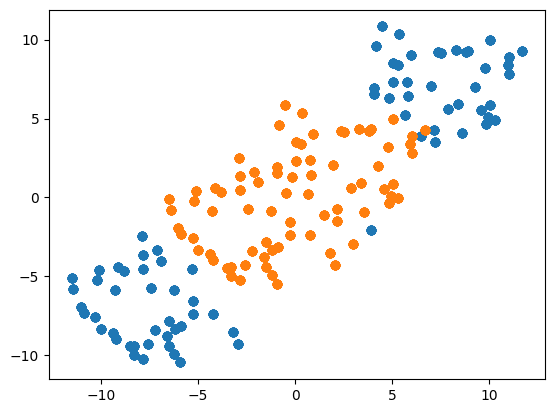

In [94]:
import jax
import jax.numpy as jnp

def squeeze_field(points, axis=jnp.array([0., 0., 1.]), center=jnp.zeros(3)):
    """
    Compute the squeezing vector field at each point.
    Each vector points radially inward toward the axis.

    Args:
        points: (N, 3) array of 3D coordinates
        axis: (3,) unit vector defining the squeeze axis
        center: (3,) point around which squeezing happens
    Returns:
        (N, 3) array of vectors representing the deformation field
    """
    # shift points to center
    p = points - center
    
    # project each point onto the axis
    axis = axis / jnp.linalg.norm(axis)
    proj = jnp.dot(p, axis)[:, None] * axis  # (N,3)
    
    # perpendicular component (distance from axis)
    radial = p - proj
    r = jnp.linalg.norm(radial, axis=1, keepdims=True) + 1e-8
    radial_dir = radial / r
    
    # inward squeeze direction (negative radial)
    # you can scale nonlinearly with r if desired (e.g. stronger near the axis)
    magnitude = -r  # proportional to distance from axis
    return magnitude * radial_dir

def apply_squeeze(points, alpha, axis=jnp.array([0., 0., 1.]), center=jnp.zeros(3)):
    """
    Apply the squeezing deformation with strength alpha ∈ [0, 1].
    """
    v = squeeze_field(points, axis, center)
    return points + alpha * v  # move along the squeeze field

# Example usage
key = jax.random.key(0)
points = atom_volume.position_pytree

# Axis along z, squeeze strength alpha = 0.3
alpha = 0.3
new_points = apply_squeeze(points, alpha=alpha, axis=jnp.array([0., 0., 1.]))


def tear_cv(positions: jnp.ndarray, normal: jnp.ndarray, offset: float, tear_amount: float):
    """
    Apply a 'tear' collective variable: separate the molecule into two halves
    along a plane defined by (normal, offset).

    Args:
        positions: (N, 3) array of atom positions.
        normal: (3,) array, unit normal vector defining the splitting plane.
        offset: float, plane offset so that the plane is {x | n·x = offset}.
        tear_amount: float, distance to separate top and bottom halves along the normal.

    Returns:
        displaced_positions: (N, 3) array after applying the tear CV.
    """
    # Compute signed distance of each point from the plane
    signed_dist = jnp.dot(positions, normal) - offset

    # Continuous smooth mask: positive side → +1, negative side → -1
    # Use tanh for differentiability instead of hard sign
    smooth_sign = jnp.tanh(10.0 * signed_dist)

    # Displace along the normal vector
    displacement = (tear_amount / 2.0) * smooth_sign[:, None] * normal[None, :]

    displaced_positions = positions + displacement
    return displaced_positions

new_points = tear_cv(points, normal=jnp.array([1., 1, 0.]), offset=0.0, tear_amount=1.0)
plt.scatter(new_points[:,0], new_points[:,1])
plt.scatter(points[:,0], points[:,1])

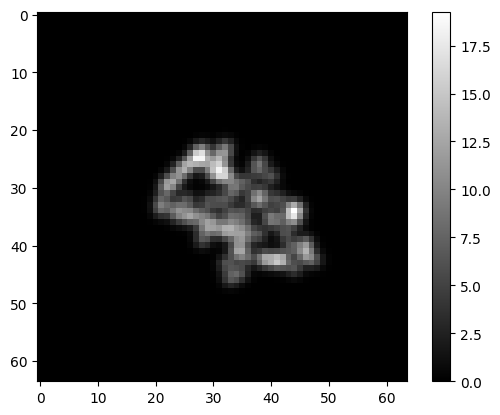

In [285]:
pixel_size, shape = 0.5, (64, 64)
pad_options = dict(shape=(64, 64))
image_config = cxs.BasicImageConfig(
    shape, pixel_size, voltage_in_kilovolts=300.0, pad_options=pad_options
)
width = 0.5
cv = 0.0
volume = gaussian_volume = cxs.GaussianMixtureVolume(
            tear_cv(points, normal=jnp.array([1., 1, 0.]), offset=0.0, tear_amount=cv) + 1.0,
            amplitudes=1.0,
            variances=width**2,
        )
gaussian_integrator = cxs.GaussianMixtureProjection()
proj_ref = gaussian_integrator.integrate(
            gaussian_volume, image_config, outputs_real_space=True
        )
plt.imshow(proj_ref, cmap='gray')
plt.colorbar()

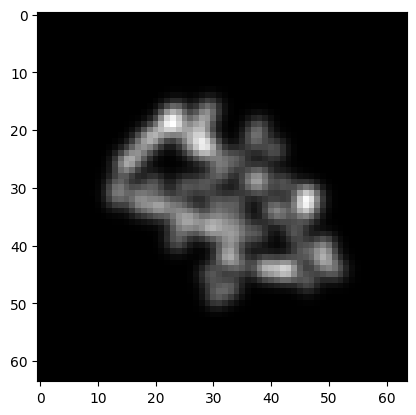

In [103]:
def apply_rotation_and_cv(volume, rotation_matrix, cv_scalar):
    # atom_positions = apply_squeeze(atom_volume.position_pytree, cv_scalar)
    # rotated_positions = atom_positions @ rotation_matrix.T
    # volume = eqx.tree_at(
    #     lambda v: v.position_pytree, volume, rotated_positions
    # )
    # proj_ref = fft_integrator.integrate(
    #     volume, image_config, outputs_real_space=True
    # )
    # print(volume.positions)
    # atom_positions = apply_squeeze(volume.positions, cv_scalar)
    new_positions = tear_cv(volume.positions, normal=jnp.array([1., 1, 0.]), offset=0.0, tear_amount=cv_scalar)
    rotated_positions = new_positions @ rotation_matrix.T
    volume_updated = eqx.tree_at(lambda v: v.positions, volume, rotated_positions)
    proj_ref = gaussian_integrator.integrate(
            volume_updated, image_config, outputs_real_space=True
        )
    return proj_ref

proj_inf = apply_rotation_and_cv(gaussian_volume, rotation_matrix=jnp.array([[1,0,0],[0,1,0],[0,0,1]]), cv_scalar=0)
plt.imshow(proj_inf, cmap='gray')

In [9]:
from goto_swap.backends.jax import emd_1d_sorted_jax_differentiable

In [98]:
theta = 0 # 45 degrees
n_pix = pad_options['shape'][0]
xm, ym = jnp.meshgrid(
    jnp.linspace(-n_pix // 2, n_pix // 2 - 1, n_pix),
    jnp.linspace(-n_pix // 2, n_pix // 2 - 1, n_pix),
    indexing='ij',
)
xy = jnp.stack([xm, ym], axis=-1)
project = jnp.tensordot(xy, jnp.array([jnp.cos(theta), jnp.sin(theta)]), axes=1)
u = project.flatten()
# translate_gt = -10
# v = project.flatten() #+ translate_gt  # shifted projection
proj_inf = apply_rotation_and_cv(volume, rotation_matrix=jnp.array([[1,0,0],[0,1,0],[0,0,1]]), cv_scalar=1.0)
u_weights = proj_inf.flatten() 
u_weights = u_weights / jnp.sum(u_weights)
# v_weights = proj_ref.flatten()
idx_a = jnp.argsort(u)
a_sorted = u_weights[idx_a]
x_a_sorted = u[idx_a]

In [11]:
# sort x_a and x_b
# idx_a = jnp.argsort(u)
# idx_b = jnp.argsort(v)

# x_a_sorted = u[idx_a]
# x_b_sorted = v[idx_b]
# a_sorted = u_weights[idx_a]
# b_sorted = v_weights[idx_b]

# # evaluate your function
# loss = emd_1d_sorted_jax_differentiable(x_a_sorted, x_b_sorted, a_sorted, b_sorted)

In [12]:
# import jax
# import jax.numpy as jnp

# def loss_for_pose_and_cv(rotation_matrix, cv_scalar, key):
#     image = apply_rotation_and_cv(atom_volume, rotation_matrix, cv_scalar)
#     v_weights = image.flatten()
#     loss = 0.0

#     n_rotations = 10
#     n_pix_samples = int(len(v_weights) / 1)

#     for idx, theta in enumerate(jnp.linspace(0, jnp.pi, n_rotations, endpoint=False)):
#         project = jnp.tensordot(xy, jnp.array([jnp.cos(theta), jnp.sin(theta)]), axes=1)
#         v = project.flatten()

#         # split off a new key for this rotation
#         key, subkey = jax.random.split(key)
#         perm = jax.random.permutation(subkey, len(v))[:n_pix_samples]
#         v = v[perm]

#         idx_b = jnp.argsort(v)
#         x_b_sorted = v[idx_b]
#         b_sorted = v_weights[perm][idx_b]

#         loss += emd_1d_sorted_jax_differentiable(x_a_sorted, x_b_sorted, a_sorted, b_sorted)

#     return loss, key  # return the updated key so it can be reused safely

# key = jax.random.key(0)

# cvs = jnp.linspace(-0.5, 0.5, 20)
# losses = []
# for cv in cvs:
#     key, subkey = jax.random.split(key)
#     loss_val, key = loss_for_pose_and_cv(jnp.eye(3), cv, subkey)
#     losses.append(loss_val)

# plt.plot(cvs, losses)


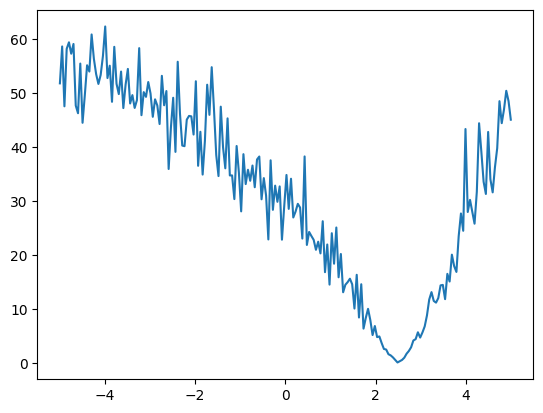

In [115]:
import jax
import jax.numpy as jnp

proj_inf = apply_rotation_and_cv(volume, rotation_matrix=jnp.eye(3), cv_scalar=2.5) 
u_weights = proj_inf.flatten() 
u_weights = u_weights / jnp.sum(u_weights)
# v_weights = proj_ref.flatten()
idx_a = jnp.argsort(u)
a_sorted = u_weights[idx_a]
x_a_sorted = u[idx_a]

def loss_for_pose_and_cv(rotation_matrix, cv_scalar, grid, n_rotations, n_pix_samples, key):
    image = apply_rotation_and_cv(volume, rotation_matrix, cv_scalar) 
    v_weights = image.flatten()
    v_weights = v_weights / v_weights.sum()  # normalize
    # n_pix_samples = len(v_weights)

    thetas = jnp.linspace(0, jnp.pi, n_rotations, endpoint=False)
    keys = jax.random.split(key, len(thetas))

    def loss_per_theta(theta, key):
        project = jnp.tensordot(grid, jnp.array([jnp.cos(theta), jnp.sin(theta)]), axes=1).flatten()
        # perm = jnp.arange(n_pix_samples)
        perm = jax.random.permutation(key, len(project))[:n_pix_samples]

        v = project[perm]
        idx_ab = jnp.argsort(v)
        x_ab_sorted = v[idx_ab]
        a_sorted = u_weights[perm][idx_ab] + 1e-8
        b_sorted = v_weights[perm][idx_ab] + 1e-8

        return emd_1d_sorted_jax_differentiable(x_ab_sorted, x_ab_sorted, a_sorted , b_sorted )

    # Vectorize over all rotation angles and random keys
    losses = jax.vmap(loss_per_theta)(thetas, keys)
    return losses.sum()

# --- Example usage ---
key = jax.random.key(0)
cvs = jnp.linspace(-5, 5, 200)
n_rotations = 30
n_pix_samples = int(0.03*len(proj_ref.flatten()) )

# Vectorize over cv_scalar for speed (optional)
def loss_for_cv(cv, key):
    return loss_for_pose_and_cv(jnp.eye(3), cv, xy, n_rotations, n_pix_samples, key)

keys = jax.random.split(key, len(cvs))
losses = jax.vmap(loss_for_cv)(cvs, keys)

# If you plan to run it many times, compile it:
# loss_for_cv_jit = jax.jit(loss_for_cv)

plt.plot(cvs, losses)

In [123]:
import jax
import jax.numpy as jnp

atom_positions, atom_type = read_atoms_from_pdb('1uao_assembly.pdb', center=True, loads_properties=False)
atom_positions = atom_positions[atom_type != 1]
volume = gaussian_volume = cxs.GaussianMixtureVolume(
            atom_positions,
            amplitudes=1.0,
            variances=width**2,
        )
proj_inf = apply_rotation_and_cv(volume, rotation_matrix=jnp.eye(3), cv_scalar=2.5) 
u_weights = proj_inf.flatten()
u_weights = u_weights / jnp.sum(u_weights)
# idx_a = jnp.argsort(u)
a_sorted = u_weights[idx_a]
# x_a_sorted = u[idx_a]

# --- Loss function ---
def loss_for_pose_and_cv(image_ref, rotation_matrix, cv_scalar, grid, n_rotations, n_pix_samples, key):
    image_1 = apply_rotation_and_cv(volume, rotation_matrix, cv_scalar) 
    
    def wasserstein_random_projections(image_1, image_2, key):
        
        # return jnp.linalg.norm(image - proj_inf)
        v_weights = image_1.flatten()
        u_weights = image_2.flatten()

        thetas = jnp.linspace(0, jnp.pi, n_rotations, endpoint=False) 
        keys = jax.random.split(key, len(thetas))

        def loss_per_theta(theta, key):
            project = jnp.tensordot(grid, jnp.array([jnp.cos(theta), jnp.sin(theta)]), axes=1).flatten()
            perm = jax.random.permutation(key, len(project))[:n_pix_samples]
            x_ab = project[perm]
            sort_idx = jnp.argsort(x_ab)
            x_ab_sorted = x_ab[sort_idx]
            a_sorted = u_weights[perm][sort_idx] + 1e-8
            b_sorted = v_weights[perm][sort_idx] + 1e-8
            return emd_1d_sorted_jax_differentiable(x_ab_sorted, x_ab_sorted, a_sorted / a_sorted.sum(), b_sorted / b_sorted.sum())

        losses = jax.vmap(loss_per_theta)(thetas, keys)
        return losses.mean()
    return wasserstein_random_projections(image_1, image_ref, key)

# --- Wrapper for gradient ---
def loss_for_cv(cv, key):
    return loss_for_pose_and_cv(proj_inf, jnp.eye(3), cv, xy, n_rotations=30, n_pix_samples=100, key=key)

grad_loss_for_cv = eqx.filter_jit(eqx.filter_grad(loss_for_cv))

# --- Example gradient descent loop ---
key = jax.random.key(0)
cv = jnp.array(0.0)

# lr = 0.000003
lr = 0.003
losses = []
cvs = []
for i in range(100):
    key, subkey = jax.random.split(key)
    loss_val = loss_for_cv(cv, subkey)
    losses.append(loss_val)
    cvs.append(cv)
    grad_val = grad_loss_for_cv(cv, subkey)
    cv = cv - lr * grad_val
    if i % 1 == 0: print(f"Step {i:02d}: loss={loss_val:.6f}, grad={grad_val:.6f}, cv={cv:.3f}")

Step 00: loss=23.974899, grad=-7.753344, cv=0.023
Step 01: loss=25.847208, grad=-9.334060, cv=0.051
Step 02: loss=24.741491, grad=-9.199549, cv=0.079
Step 03: loss=25.758118, grad=-4.275904, cv=0.092
Step 04: loss=22.838779, grad=-8.470469, cv=0.117
Step 05: loss=26.437757, grad=-12.971735, cv=0.156
Step 06: loss=24.900528, grad=-8.837563, cv=0.183
Step 07: loss=19.705065, grad=-8.094228, cv=0.207
Step 08: loss=26.862770, grad=-7.665890, cv=0.230
Step 09: loss=28.141989, grad=-13.453478, cv=0.270
Step 10: loss=23.134501, grad=-10.884906, cv=0.303
Step 11: loss=22.581970, grad=-8.088813, cv=0.327
Step 12: loss=23.273390, grad=-4.045216, cv=0.339
Step 13: loss=19.011463, grad=-10.846756, cv=0.372
Step 14: loss=17.065371, grad=-9.542229, cv=0.400
Step 15: loss=18.781712, grad=-7.692973, cv=0.423
Step 16: loss=20.183043, grad=-9.989886, cv=0.453
Step 17: loss=23.116251, grad=-11.637735, cv=0.488
Step 18: loss=16.922207, grad=-8.229157, cv=0.513
Step 19: loss=21.138317, grad=-11.210137, cv=

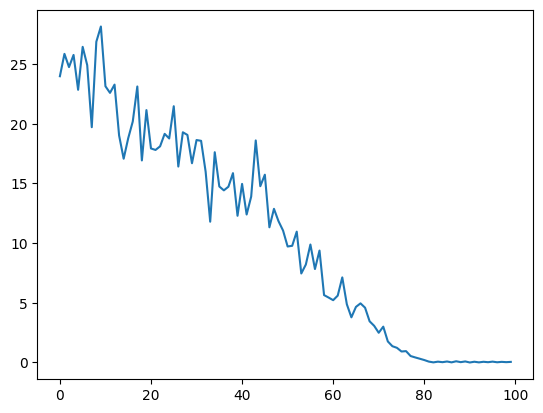

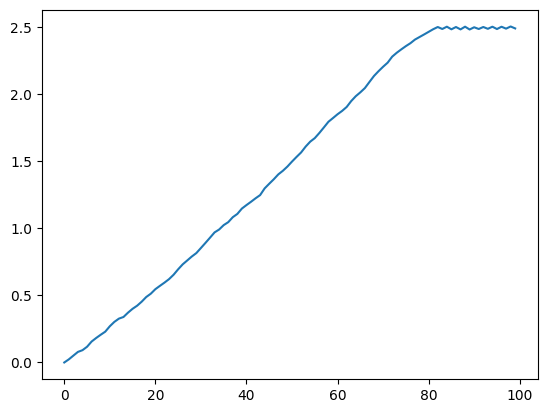

In [124]:
plt.plot(losses)
plt.show()
plt.plot(cvs)

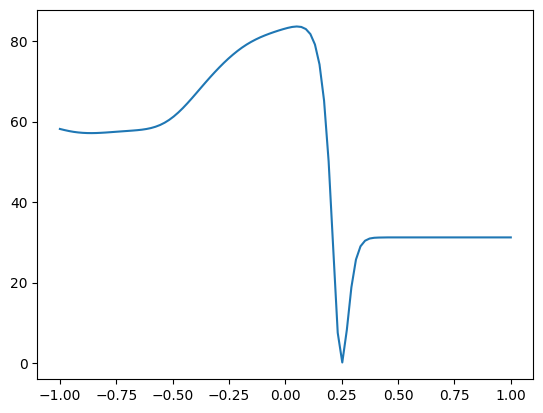

In [82]:
cv_grid = jnp.linspace(-1, 1, 100)
plt.plot(cv_grid, [loss_for_cv(cv, subkey) for cv in cv_grid])

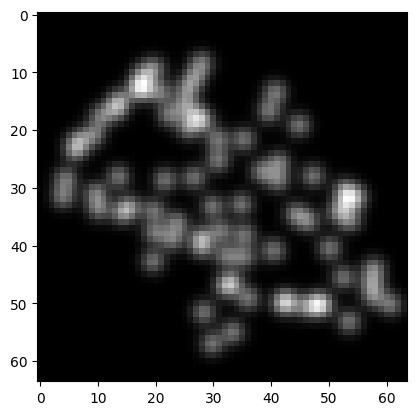

In [61]:
image = apply_rotation_and_cv(volume, jnp.eye(3), -0.5)
plt.imshow(image, cmap='gray')


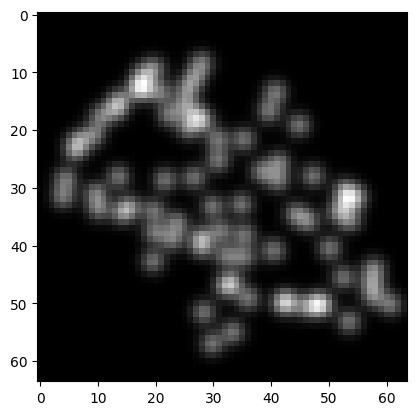

In [42]:
plt.imshow(proj_inf, cmap='gray')

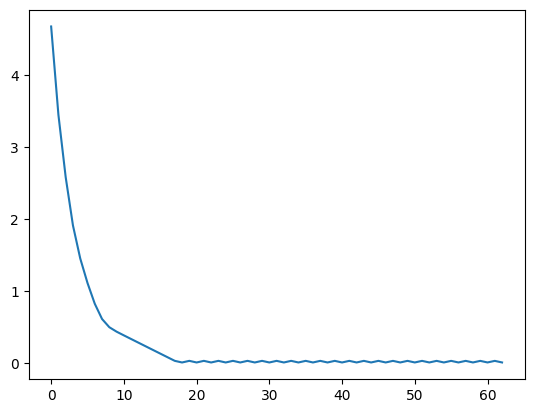

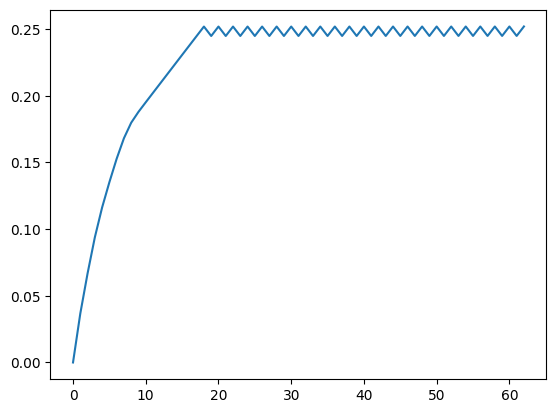

# load results and visualize

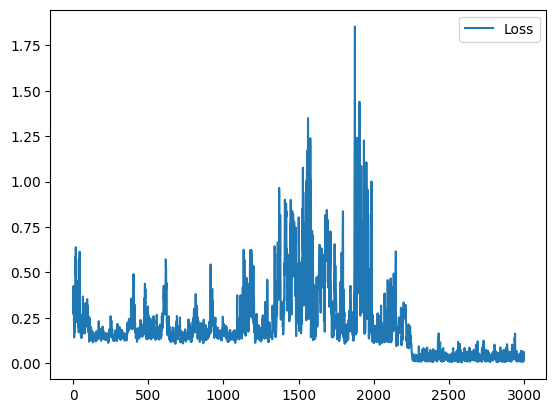

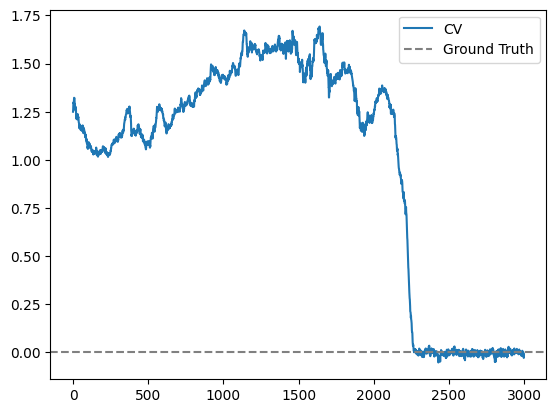

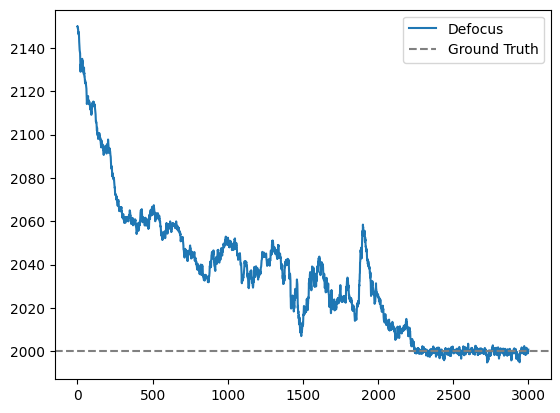

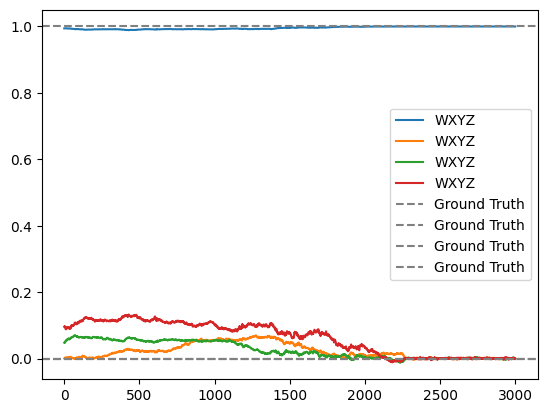

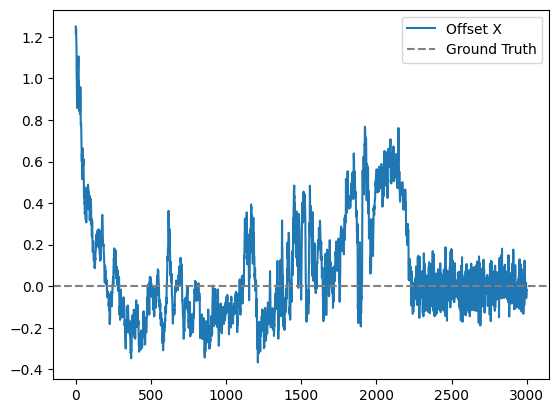

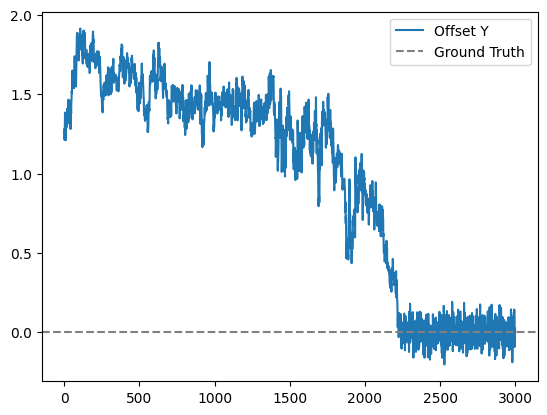

In [288]:
output = jnp.load("/Users/gw/repos/GOTO-SWAP/examples/outputs/2025-11-11/17-52-45/joint_gradient_descent_traces.npz")
losses = output['losses'].tolist()
cvs = output['cvs'].tolist()
defoci = output['defoci'].tolist()
wxyzs = output['wxyzs'].tolist()
offset_xs = output['offset_xs'].tolist()
offset_ys = output['offset_ys'].tolist()
plt.plot(losses, label="Loss")
plt.legend()
plt.show()
plt.plot(cvs, label="CV")
plt.axhline(y=0, color='gray', linestyle='--', label='Ground Truth')
plt.legend()
plt.show()
plt.plot(defoci, label="Defocus")
plt.axhline(y=2000, color='gray', linestyle='--', label='Ground Truth')
plt.legend()
plt.show()
plt.plot(wxyzs, label="WXYZ")
for quaternion_component in [1,0,0,0]:
    plt.axhline(y=quaternion_component, color='gray', linestyle='--', label='Ground Truth')
plt.legend()
plt.show()
plt.plot(offset_xs, label="Offset X")
plt.axhline(y=0, color='gray', linestyle='--', label='Ground Truth')
plt.legend()
plt.show()
plt.plot(offset_ys, label="Offset Y")
plt.axhline(y=0, color='gray', linestyle='--', label='Ground Truth')
plt.legend()
plt.show()

# scratch

In [82]:
# ...existing code...
# Gradient descent on `translate` through the EMD loss
import jax
import jax.numpy as jnp

# assumes `project` and `emd_1d_sorted_jax_differentiable` are already defined in the notebook
idx_a = jnp.argsort(u)
a_sorted = u_weights[idx_a]
x_a_sorted = u[idx_a]
# translate_gt = jnp.array(-1.0)
# v = u + translate_gt
n = project.size

def loss_for_translate(t):
    # v = project.flatten() + t + 1
    idx_b = jnp.argsort(v)
    x_b_sorted = v[idx_b] + t
    b_sorted = v_weights[idx_b]
    return emd_1d_sorted_jax_differentiable(x_a_sorted, x_b_sorted, a_sorted, b_sorted)

grad_loss = jax.jit(jax.grad(loss_for_translate))

# initialize and run simple SGD
translate = jnp.array(0.51)
lr = 0.00003
num_steps = 40

for i in range(num_steps):
    g = grad_loss(translate)
    translate = translate - lr * g
    if i % 1 == 0 or i == num_steps - 1:
        print(f"iter {i:04d} translate={float(translate):.6f} loss={float(loss_for_translate(translate)):.6f}")

print("final translate:", float(translate))
# ...existing code...

iter 0000 translate=4.089087 loss=219615.375000
iter 0001 translate=6.318347 loss=85200.070312
iter 0002 translate=7.706857 loss=33053.425781
iter 0003 translate=8.571700 loss=12823.075195
iter 0004 translate=9.110373 loss=4974.734863
iter 0005 translate=9.445890 loss=1929.946533
iter 0006 translate=9.654869 loss=748.723328
iter 0007 translate=9.785033 loss=290.467133
iter 0008 translate=9.866106 loss=112.687569
iter 0009 translate=9.916603 loss=43.717491
iter 0010 translate=9.948055 loss=16.960585
iter 0011 translate=9.967646 loss=6.580109
iter 0012 translate=9.979848 loss=2.552877
iter 0013 translate=9.987448 loss=0.990583
iter 0014 translate=9.992182 loss=0.384425
iter 0015 translate=9.995131 loss=0.149260
iter 0016 translate=9.996967 loss=0.058026
iter 0017 translate=9.998111 loss=0.022651
iter 0018 translate=9.998823 loss=0.008922
iter 0019 translate=9.999267 loss=0.003597
iter 0020 translate=9.999543 loss=0.001528
iter 0021 translate=9.999716 loss=0.000724
iter 0022 translate=9.9

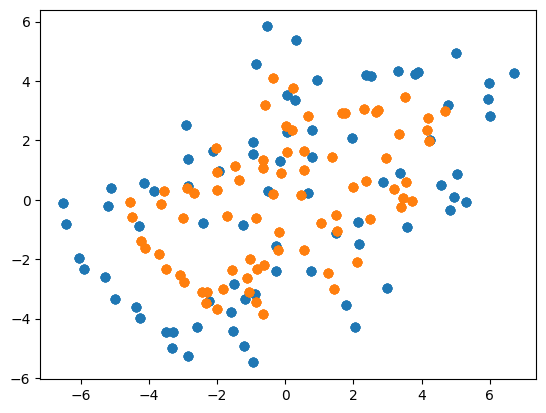

In [11]:
plt.scatter(points[:,0], points[:,1], alpha=0.5, label='Original')
plt.scatter(new_points[:,0], new_points[:,1], alpha=0.5, )

In [49]:
import plotly.graph_objects as go

In [52]:
# --- convert to numpy for plotly ---
points_np = jnp.array(points)
new_points_np = jnp.array(new_points)

# --- plotly 3D scatter ---
fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=points_np[:, 0], y=points_np[:, 1], z=points_np[:, 2],
    mode='lines+markers',
    marker=dict(size=2, color='blue', opacity=0.5),
    name='Original'
))

fig.add_trace(go.Scatter3d(
    x=new_points_np[:, 0], y=new_points_np[:, 1], z=new_points_np[:, 2],
    mode='lines+markers',
    marker=dict(size=2, color='red', opacity=0.5),
    name='Squeezed'
))

# Draw the axis line (for visual reference)
axis = jnp.array([0., 0., 1.])
center = jnp.zeros(3)
line = jnp.stack([center - 2*axis, center + 2*axis])
fig.add_trace(go.Scatter3d(
    x=line[:,0], y=line[:,1], z=line[:,2],
    mode='lines',
    line=dict(color='black', width=4),
    name='Axis'
))

fig.update_layout(
    scene=dict(
        xaxis_title='x',
        yaxis_title='y',
        zaxis_title='z',
        aspectmode='data'
    ),
    title=f"3D Squeeze Field (alpha={alpha})"
)

fig.show()